# Notebook 2: click regressor (BeepFake / ExDDV)

Predicts where a human would click on a 224x224 face crop (the artifact position), so notebook 4 can mask around it. Backbone: DeiT-small (ViT, ~22M params) + small regression head, trained on the crops from notebook 1.

**Needs:** the dataset with notebook 1's output (`metadata.csv` + `crops/`) attached, internet on (downloads DeiT-small), GPU T4 (only GPU 0 is used).

**Honest framing of the target.** Clicks are annotated on only ~5 frames per video, so each of our 5 sampled frames gets the *nearest-in-time* click, often tens or hundreds of frames away. That label is noisy. So: (1) the loss is weighted by `1 / (1 + dist/30)`, (2) the 127 videos whose click frame indices run past the video length are excluded from training and evaluation, (3) results are reported per distance bucket and against two constant baselines. **If the regressor does not clearly beat "always predict the mean click", masking around its prediction adds nothing.**

**Outputs** (`/kaggle/working/click/`): `best.pt`, `click_preds.csv` (predicted click per frame, all videos).

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import json, time, random, math
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "turn on a GPU (T4) in the notebook settings"
DEV = torch.device("cuda:0")
print(torch.__version__, torch.cuda.get_device_name(0))

INPUT_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working/click"); OUT_DIR.mkdir(parents=True, exist_ok=True)
BACKBONE = "facebook/deit-small-patch16-224"
N_FRAMES, CROP = 5, 224
EPOCHS, BS = 15, 64
LR_BB, LR_HEAD, WD = 5e-5, 1e-3, 0.05
DIST_SCALE = 30          # frames; weight = 1 / (1 + dist / DIST_SCALE)
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

2.11.0+cu130 Tesla T4


## 1. Load notebook 1's output and check the click-frame problem

In [2]:
cands = [p for p in INPUT_ROOT.rglob("metadata.csv") if (p.parent / "crops").is_dir()]
assert cands, "no metadata.csv with a sibling crops/ folder under /kaggle/input. Check how the output was uploaded."
PREP = cands[0].parent
print("prep dir:", PREP)
meta = pd.read_csv(PREP / "metadata.csv")
for c in ["frame_idx","box","det_sources","crop_paths","clicks_crop","click_targets"]:
    meta[c] = meta[c].map(json.loads)
print(meta.shape, meta.split.value_counts().to_dict())

# why do some click frame indices run past the end of the video?
meta["max_click"] = meta.clicks_crop.map(lambda l: max(c["frame"] for c in l))
meta["ratio"] = meta.max_click / meta.n_frames
bad = meta[meta.click_beyond_video]
print(f"\nclick index beyond video length: {len(bad)} videos")
print("max_click / n_frames for those:", bad.ratio.describe().round(2).to_dict())
print("share by manipulation:", meta.groupby("manipulation").click_beyond_video.mean().round(3).to_dict())
print("by frame size:", bad.groupby(["W","H"]).size().sort_values(ascending=False).head(5).to_dict())
print("(ratios near 1.0 = off by a few frames or a bad frame count; ratios near 2 or 0.5-fold = fps mismatch)")

prep dir: /kaggle/input/datasets/kishlaytejeswi/vlm-nlp/notebook1
(2993, 16) {'train': 2453, 'test': 271, 'val': 269}

click index beyond video length: 127 videos
max_click / n_frames for those: {'count': 127.0, 'mean': 1.0, 'std': 0.0, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 1.0}
share by manipulation: {'Face2Face': 0.021, 'FaceShifter': 0.031, 'FaceSwap': 0.075}
by frame size: {(1280, 720): 44, (640, 480): 26, (1920, 1080): 20, (854, 480): 14, (656, 480): 10}
(ratios near 1.0 = off by a few frames or a bad frame count; ratios near 2 or 0.5-fold = fps mismatch)


In [3]:
valid = (~meta.click_beyond_video.values) & (meta.click_targets.map(len).values == N_FRAMES)
print("videos usable for training/eval:", int(valid.sum()), "of", len(meta))
for sp in ["train","val","test"]:
    print(sp, int(((meta.split == sp).values & valid).sum()), "usable /", int((meta.split == sp).sum()))

videos usable for training/eval: 2866 of 2993
train 2350 usable / 2453
val 254 usable / 269
test 262 usable / 271


## 2. Load all crops into RAM (~2.2 GB) and build targets

In [4]:
N = len(meta)
imgs = np.zeros((N, N_FRAMES, CROP, CROP, 3), np.uint8)
def load_video(i):
    for j, p in enumerate(meta.crop_paths.iloc[i]):
        im = cv2.imread(str(PREP / p))
        if im is None: raise FileNotFoundError(PREP / p)
        imgs[i, j] = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
with ThreadPoolExecutor(8) as ex:
    list(tqdm(ex.map(load_video, range(N)), total=N))

tgt = np.zeros((N, N_FRAMES, 2), np.float32); dist = np.full((N, N_FRAMES), 1e4, np.float32)
for i, l in enumerate(meta.click_targets):
    for j, t in enumerate(l):
        tgt[i, j] = (t["x"], t["y"]); dist[i, j] = t["dist"]
tgt = np.clip(tgt, 0, 1)     # 0.2% of clicks fall just outside the crop
print(imgs.shape, "RAM GB:", round(imgs.nbytes / 1e9, 2))

def pairs(split):
    ids = np.where((meta.split == split).values & valid)[0]
    return np.array([(v, j) for v in ids for j in range(N_FRAMES)])
P_tr, P_va, P_te = pairs("train"), pairs("val"), pairs("test")
print("frame samples train/val/test:", len(P_tr), len(P_va), len(P_te))
print("target mean (x, y):", tgt[P_tr[:,0], P_tr[:,1]].mean(0).round(3), "| std:", tgt[P_tr[:,0], P_tr[:,1]].std(0).round(3))

  0%|          | 0/2993 [00:00<?, ?it/s]

(2993, 5, 224, 224, 3) RAM GB: 2.25
frame samples train/val/test: 11750 1270 1310
target mean (x, y): [0.495 0.538] | std: [0.135 0.17 ]


## 3. Metrics and constant baselines

In [5]:
def errors(P, pred):
    t = tgt[P[:, 0], P[:, 1]]; d = dist[P[:, 0], P[:, 1]]
    return np.linalg.norm(pred - t, axis=1), d      # units: fraction of the crop side

def summarize(name, P, pred):
    e, d = errors(P, pred); w = 1 / (1 + d / DIST_SCALE)
    row = {"model": name, "weighted_err_px": (w * e).sum() / w.sum() * CROP, "mean_err_px": e.mean() * CROP,
           "median_err_px": np.median(e) * CROP, "hit@0.2side": (e <= 0.2).mean()}
    for lo, hi, nm in [(0, 15, "d<=15"), (16, 60, "d16-60"), (61, 1e9, "d>60")]:
        m = (d >= lo) & (d <= hi)
        row[f"err_px {nm}"] = e[m].mean() * CROP if m.any() else np.nan
    return row

mean_click = tgt[P_tr[:, 0], P_tr[:, 1]].mean(0)
base_rows = [summarize("constant: centre", P_va, np.full((len(P_va), 2), 0.5)),
             summarize("constant: train-mean click", P_va, np.tile(mean_click, (len(P_va), 1)))]
pd.DataFrame(base_rows).round(3)

,model,weighted_err_px,mean_err_px,median_err_px,hit@0.2side,err_px d<=15,err_px d16-60,err_px d>60
0,constant: centre,46.712,46.266,44.543,0.510,47.395,46.346,45.680
1,constant: train-mean click,45.727,45.307,42.315,0.547,46.473,45.280,44.765


## 4. Model and training

In [6]:
from transformers import AutoModel
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)

class ClickNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.bb = AutoModel.from_pretrained(BACKBONE)
        d = self.bb.config.hidden_size
        self.head = nn.Sequential(nn.LayerNorm(2 * d), nn.Linear(2 * d, 256), nn.GELU(), nn.Linear(256, 2))
    def forward(self, x):
        h = self.bb(pixel_values=x).last_hidden_state
        return torch.sigmoid(self.head(torch.cat([h[:, 0], h[:, 1:].mean(1)], -1)))

model = ClickNet().to(DEV)
print("params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))

def batch_x(P):
    x = torch.from_numpy(imgs[P[:, 0], P[:, 1]]).to(DEV).permute(0, 3, 1, 2).float().div_(255)
    return (x - MEAN) / STD

@torch.no_grad()
def predict(P, bs=128):
    model.eval(); out = []
    for s in range(0, len(P), bs):
        x = batch_x(P[s:s + bs])
        with torch.autocast("cuda", dtype=torch.float16):
            p1 = model(x).float(); p2 = model(torch.flip(x, dims=[3])).float()
        p2 = torch.stack([1 - p2[:, 0], p2[:, 1]], 1)       # un-flip x
        out.append(((p1 + p2) / 2).cpu())
    return torch.cat(out).numpy()

opt = torch.optim.AdamW([{"params": model.bb.parameters(), "lr": LR_BB},
                         {"params": model.head.parameters(), "lr": LR_HEAD}], weight_decay=WD)
steps_per_epoch = len(P_tr) // BS; total = EPOCHS * steps_per_epoch; warm = steps_per_epoch
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
scaler = torch.amp.GradScaler("cuda")
print("steps/epoch:", steps_per_epoch)

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 88.3MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/deit-small-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


params (M): 22.0
steps/epoch: 183


In [7]:
hist, best = [], 1e9
for ep in range(EPOCHS):
    model.train(); t0 = time.time(); perm = np.random.permutation(len(P_tr)); run = 0.0
    for s in range(steps_per_epoch):
        P = P_tr[perm[s * BS:(s + 1) * BS]]
        x = batch_x(P)
        y = torch.from_numpy(tgt[P[:, 0], P[:, 1]]).to(DEV)
        w = torch.from_numpy(1 / (1 + dist[P[:, 0], P[:, 1]] / DIST_SCALE)).to(DEV)
        flip = torch.rand(len(P), device=DEV) < 0.5                       # horizontal flip, x -> 1 - x
        x = torch.where(flip.view(-1, 1, 1, 1), torch.flip(x, dims=[3]), x)
        y = torch.where(flip.view(-1, 1), torch.stack([1 - y[:, 0], y[:, 1]], 1), y)
        with torch.autocast("cuda", dtype=torch.float16):
            pred = model(x)
        loss = (nn.functional.smooth_l1_loss(pred.float(), y, beta=0.05, reduction="none").sum(1) * w).sum() / w.sum()
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        run += loss.item()
    v = summarize("val", P_va, predict(P_va))
    hist.append({"epoch": ep + 1, "train_loss": run / steps_per_epoch, **v})
    flag = ""
    if v["weighted_err_px"] < best:
        best = v["weighted_err_px"]; torch.save(model.state_dict(), OUT_DIR / "best.pt"); flag = " *best"
    print(f"ep {ep+1:2d}  loss {run/steps_per_epoch:.4f}  val weighted err {v['weighted_err_px']:.1f}px  hit@0.2 {v['hit@0.2side']:.3f}  ({time.time()-t0:.0f}s){flag}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

ep  1  loss 0.2072  val weighted err 44.8px  hit@0.2 0.532  (41s) *best
ep  2  loss 0.1854  val weighted err 42.9px  hit@0.2 0.549  (38s) *best
ep  3  loss 0.1688  val weighted err 44.1px  hit@0.2 0.543  (41s)
ep  4  loss 0.1559  val weighted err 45.6px  hit@0.2 0.527  (41s)
ep  5  loss 0.1426  val weighted err 44.8px  hit@0.2 0.535  (41s)
ep  6  loss 0.1304  val weighted err 44.6px  hit@0.2 0.539  (41s)
ep  7  loss 0.1199  val weighted err 44.3px  hit@0.2 0.531  (41s)
ep  8  loss 0.1107  val weighted err 44.6px  hit@0.2 0.536  (41s)
ep  9  loss 0.0979  val weighted err 44.1px  hit@0.2 0.529  (41s)
ep 10  loss 0.0862  val weighted err 44.0px  hit@0.2 0.539  (41s)
ep 11  loss 0.0747  val weighted err 44.6px  hit@0.2 0.524  (41s)
ep 12  loss 0.0648  val weighted err 44.5px  hit@0.2 0.519  (41s)
ep 13  loss 0.0571  val weighted err 44.6px  hit@0.2 0.518  (41s)
ep 14  loss 0.0512  val weighted err 44.7px  hit@0.2 0.521  (41s)
ep 15  loss 0.0502  val weighted err 44.7px  hit@0.2 0.519  (41s

## 5. Test results vs baselines

In [8]:
model.load_state_dict(torch.load(OUT_DIR / "best.pt", map_location=DEV))
pred_te = predict(P_te)
rows = [summarize("constant: centre", P_te, np.full((len(P_te), 2), 0.5)),
        summarize("constant: train-mean click", P_te, np.tile(mean_click, (len(P_te), 1))),
        summarize("ViT regressor", P_te, pred_te)]
res = pd.DataFrame(rows).round(3); display(res)

r, b = res.iloc[2], res.iloc[1]
print(f"\nregressor vs mean-click baseline: weighted error {r.weighted_err_px:.1f}px vs {b.weighted_err_px:.1f}px "
      f"({100*(1-r.weighted_err_px/b.weighted_err_px):.0f}% lower); hit@0.2side {r['hit@0.2side']:.3f} vs {b['hit@0.2side']:.3f}")
t_te = tgt[P_te[:, 0], P_te[:, 1]]
print("spread (std x, y)  targets:", t_te.std(0).round(3), "| predictions:", pred_te.std(0).round(3),
      "(predictions much narrower than targets = mostly regressing to the mean)")
if r.weighted_err_px > 0.9 * b.weighted_err_px:
    print("WARNING: gain over the constant baseline is small. Masking around these predictions may add little; "
          "consider the soft/centre-prior variants or a larger backbone before notebook 4.")

,model,weighted_err_px,mean_err_px,median_err_px,hit@0.2side,err_px d<=15,err_px d16-60,err_px d>60
0,constant: centre,45.782,46.343,46.020,0.460,46.180,44.638,47.242
1,constant: train-mean click,45.148,45.450,43.407,0.532,45.624,44.173,45.987
2,ViT regressor,41.441,41.533,39.981,0.577,42.353,39.989,41.904



regressor vs mean-click baseline: weighted error 41.4px vs 45.1px (8% lower); hit@0.2side 0.577 vs 0.532
spread (std x, y)  targets: [0.143 0.17 ] | predictions: [0.002 0.098] (predictions much narrower than targets = mostly regressing to the mean)


## 6. Predict a click for every frame of every video and save

In [9]:
P_all = np.array([(v, j) for v in range(N) for j in range(N_FRAMES)])
pred_all = predict(P_all).reshape(N, N_FRAMES, 2)
out = pd.DataFrame({"key": meta.key, "split": meta.split, "used_in_training_or_eval": valid,
                    "pred_clicks": [json.dumps(np.round(pred_all[i], 4).tolist()) for i in range(N)]})
out.to_csv(OUT_DIR / "click_preds.csv", index=False)
print("saved", OUT_DIR / "click_preds.csv", out.shape)
print("NOTE: predictions on train videos are slightly better than they will be on unseen videos (the model was fit on those frames).")

saved /kaggle/working/click/click_preds.csv (2993, 4)
NOTE: predictions on train videos are slightly better than they will be on unseen videos (the model was fit on those frames).


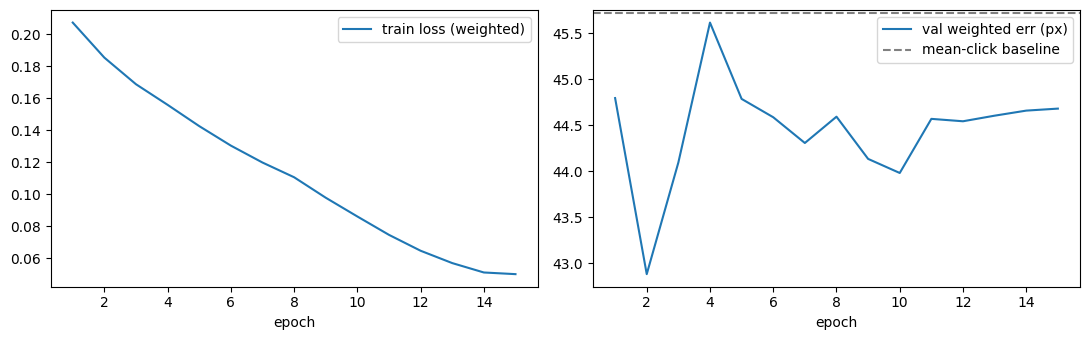

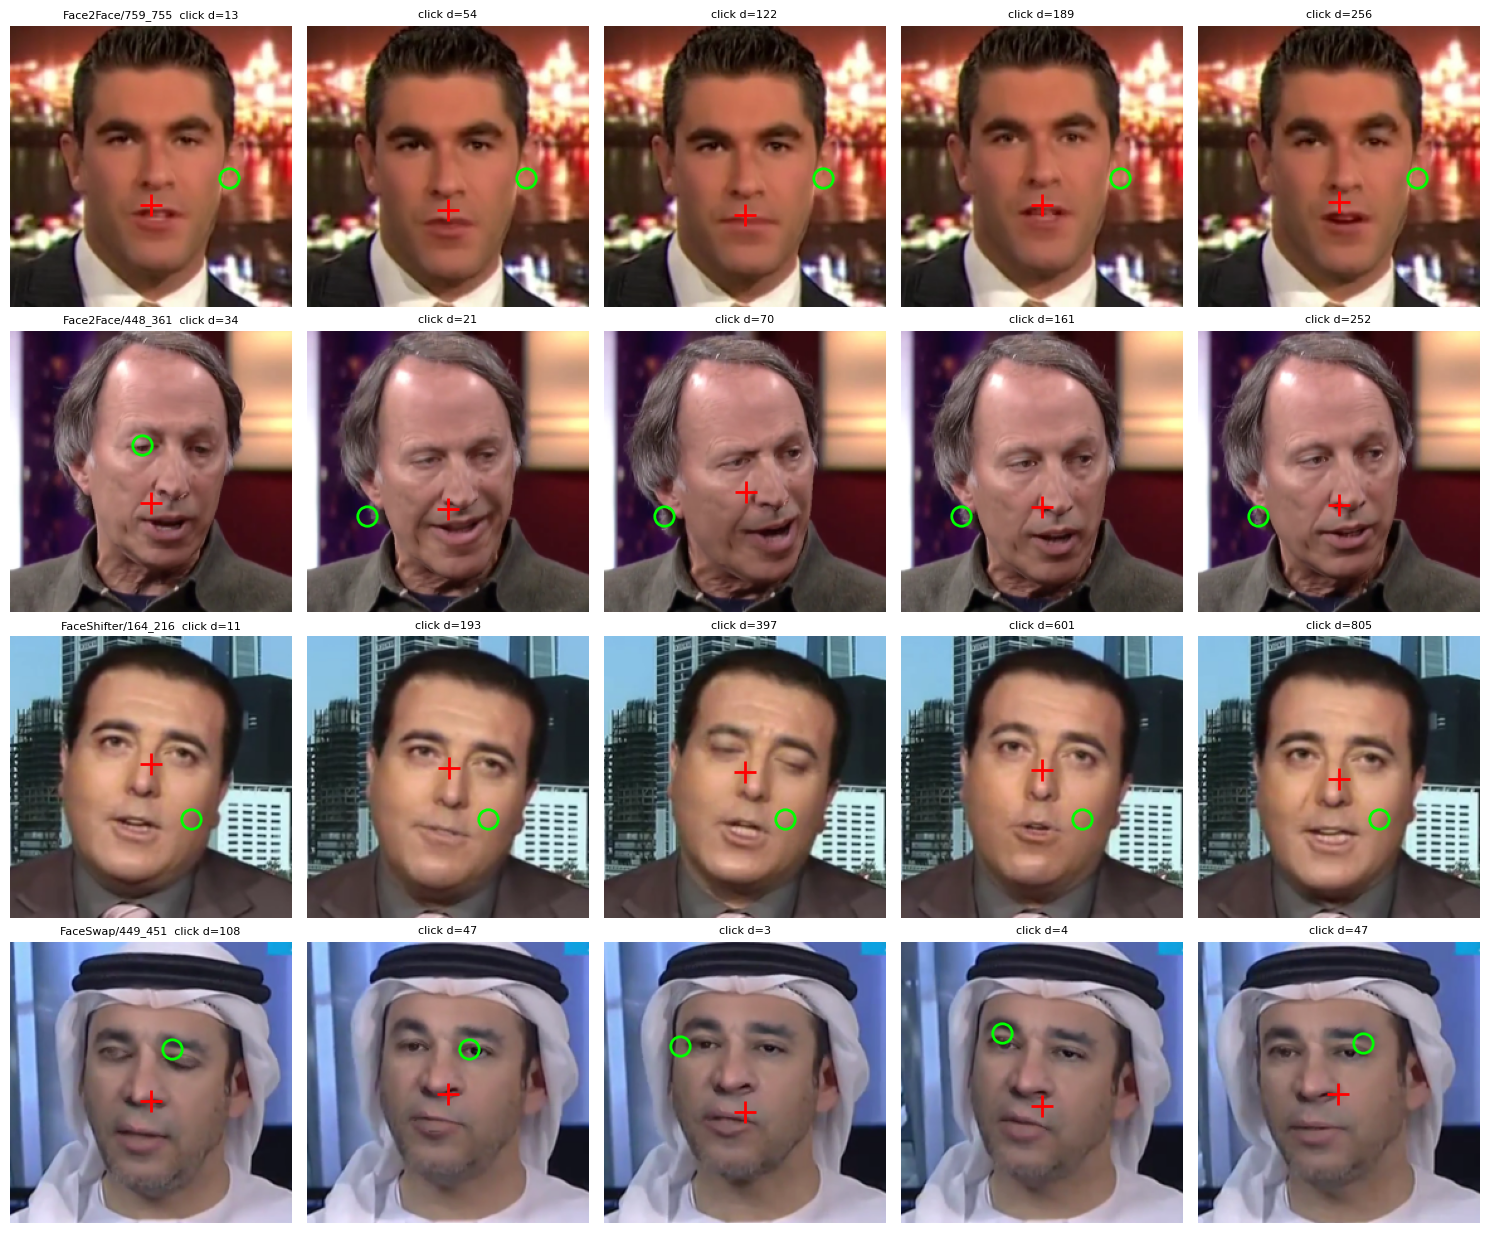

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h = pd.DataFrame(hist)
ax[0].plot(h.epoch, h.train_loss, label="train loss (weighted)"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.weighted_err_px, label="val weighted err (px)"); ax[1].axhline(base_rows[1]["weighted_err_px"], ls="--", c="gray", label="mean-click baseline")
ax[1].legend(); ax[1].set_xlabel("epoch"); plt.tight_layout(); plt.show()

# val examples: green circle = human (nearest) click, red cross = prediction
vids = random.Random(1).sample(sorted(set(P_va[:, 0])), 4)
fig, axes = plt.subplots(len(vids), N_FRAMES, figsize=(3 * N_FRAMES, 3.1 * len(vids)), squeeze=False)
for r_, v in enumerate(vids):
    for j in range(N_FRAMES):
        a = axes[r_][j]; a.imshow(imgs[v, j]); a.axis("off")
        a.plot(*(tgt[v, j] * CROP), "o", mfc="none", mec="lime", ms=14, mew=2)
        a.plot(*(pred_all[v, j] * CROP), "r+", ms=16, mew=2)
        a.set_title((meta.key[v] + "  " if j == 0 else "") + f"click d={int(dist[v, j])}", fontsize=8)
plt.tight_layout(); plt.show()

## Next
Attach `click_preds.csv` (and `best.pt` if you want it) as a dataset. Notebook 3 (baseline BLIP-2) does not need it; notebook 4 (click-masked) does.

Limitations to state in the write-up: nearest-in-time click targets (noisy, weighted by distance); 127 videos excluded for inconsistent click frame indices; predictions on training videos are optimistic because the regressor was fit on them.